# Geometry-aligned classification of unfocused SAR phase histories

This notebook implements the application-level experiment linking the
query-induced circuit bias to synthetic-aperture-radar image formation. It is
intentionally a **controlled SAR-like experiment**, not a claim to reproduce a
complete operational SAR processing chain.

The input is a small complex phase-history patch in azimuth-wavenumber and
range-wavenumber coordinates, upstream of focusing. Its nonseparable phase is
generated from the local \(\omega\)-\(k\) dispersion surface

\[
k_y(k_x,k_r)=\sqrt{k_r^2-k_x^2}.
\]

Carrier frequency, range-frequency sampling, azimuth-wavenumber sampling,
squint, and the task's reference slant range determine a scalar query
\(f^\star_{\rm geom}\) **before any scene or label is sampled**. The circuit
does not implement the exact inverse. Instead it applies the leading mixed
term of the geometry, a compact bilinear phase correction realizable with
\(n^2=9\) cross-register \(R_{ZZ}\) gates for two three-qubit registers.

Each scene contains one labeled target near the reference range, several
off-range clutter scatterers, continuous subcell offsets, small range jitter,
complex Gaussian sensor noise, and a fixed label-independent azimuth-channel
phase response. The label is the target's azimuth cell. All models receive the
same amplitude-encoded phase history and the same shallow trainable readout.
They differ only in the fixed query:

- **geometry aligned:** \(f=f^\star_{\rm geom}\);
- **mismatched:** \(f=f^\star_{\rm geom}/2\);
- **no query:** \(f=0\).

The three-panel manuscript figure tests whether accuracy peaks at the
geometry-derived value, whether a training-only empirical optimum tracks the
geometry across reference ranges, and whether alignment improves sample
efficiency. The empirical recovery panel is a diagnostic only; the aligned
classifier always receives its query from geometry and never selects it using
test data.

The default `smoke` profile validates every stage. Set `PROFILE = "paper"`,
restart the kernel, and run all cells for manuscript results.

In [1]:
# =============================================================================
# Configuration
# =============================================================================
from pathlib import Path
import hashlib
import json
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import optax

jax.config.update("jax_enable_x64", True)

PROFILE = "paper"

# Two 3-qubit registers: azimuth wavenumber and range wavenumber.
N = 3
Q = 2**N

# X-band-like local acquisition patch. k_r is the two-way range wavenumber.
C0 = 299_792_458.0
CARRIER_HZ = 10.0e9
RANGE_FREQUENCY_STEP_HZ = 5.0e6
AZIMUTH_WAVENUMBER_CENTER = 125.0       # rad/m; nonzero value represents squint
AZIMUTH_WAVENUMBER_STEP = 1.25          # rad/m per discrete sample
REFERENCE_RANGE_M = 3700.0

# Primary data model.
SNR_DB = 10.0
N_CLUTTER = 4
CLUTTER_RMS = 1.25
AZIMUTH_SUBCELL_JITTER = 0.48           # maximum offset in cell-width units
TARGET_RANGE_JITTER = 0.01              # fractional standard deviation
CLUTTER_RANGE_RATIO = (0.45, 1.55)

# Fixed, label-independent azimuth-channel phase response. It prevents the
# common Fourier readout from solving the aligned task without learning, while
# remaining exactly representable by the shared trainable residual circuit.
SENSOR_Z_PHASES = np.array([1.5, -1.7, 1.0])

# Capacity-matched trainable readout: 2 layers x 3 qubits x (RY,RZ).
READOUT_LAYERS = 2

PROFILES = {
    "smoke": dict(
        n_draws=1,
        recovery_draws=1,
        n_train_scan=128,
        n_test=800,
        efficiency_ns=[32, 128],
        n_restarts=2,
        adam_steps=120,
        adam_lr=0.04,
        global_points=7,
        recovery_ranges_m=[3000.0, 3700.0, 4400.0],
        recovery_f_points=7,
        bootstrap_samples=200,
    ),
    "paper": dict(
        n_draws=10,
        recovery_draws=6,
        n_train_scan=1024,
        n_test=5000,
        efficiency_ns=[32, 64, 128, 256, 512, 1024],
        n_restarts=8,
        adam_steps=900,
        adam_lr=0.035,
        global_points=33,
        recovery_ranges_m=[2600.0, 3150.0, 3700.0, 4250.0, 4800.0],
        recovery_f_points=27,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

BASE_SEED = 271828
OUTDIR = Path("./sar_geometry_outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

print(
    f"profile={PROFILE} | Q={Q} classes | trainable parameters="
    f"{READOUT_LAYERS * N * 2} | draws={P['n_draws']}"
)
if PROFILE != "paper":
    print("SMOKE PROFILE: its numerical values are not manuscript results.")

profile=paper | Q=8 classes | trainable parameters=12 | draws=10


## From acquisition geometry to the fixed query

For the sampled range frequencies and azimuth wavenumbers,

\[
k_{r,d}=\frac{4\pi}{c}
\left[f_c+\left(d-\frac{Q-1}{2}\right)\Delta f_r\right],
\qquad
k_{x,a}=k_{x,0}+\left(a-\frac{Q-1}{2}\right)\Delta k_x.
\]

The \(\omega\)-\(k\) surface is
\(k_{y,ad}=\sqrt{k_{r,d}^2-k_{x,a}^2}\). Terms depending only on
\(a\) or only on \(d\) are separable single-register phases and are removed,
leaving the interaction

\[
\widetilde{k}_{y,ad}
=k_{y,ad}-\overline{k}_{y,a\cdot}
-\overline{k}_{y,\cdot d}+\overline{k}_y.
\]

Around the patch center,

\[
\widetilde{k}_{y,ad}
\simeq
\kappa_{xr}\Delta k_x\Delta k_r\,\widetilde a\widetilde d,
\qquad
\kappa_{xr}
=\left.
\frac{\partial^2 k_y}{\partial k_x\partial k_r}
\right|_0
=\frac{k_{x,0}k_{r,0}}
{(k_{r,0}^2-k_{x,0}^2)^{3/2}}.
\]

A target at reference slant range \(R_0\) therefore has the leading
nonseparable phase

\[
f^\star_{\rm geom}\,\widetilde a\widetilde d,
\qquad
f^\star_{\rm geom}
=R_0\kappa_{xr}\Delta k_x\Delta k_r.
\]

This is the query supplied to the circuit. The generator
\(\widetilde a\widetilde d\) is only the leading approximation; scenes are
generated from the full sampled interaction \(\widetilde{k}_{y,ad}\). Thus a
successful aligned model cannot be attributed to constructing the data with
the exact inverse circuit.

In [2]:
# =============================================================================
# Geometry and query generator
# =============================================================================
TWO_PI = 2 * np.pi
INDEX = np.arange(Q, dtype=float)
CENTERED = INDEX - (Q - 1) / 2
CELL_WIDTH = TWO_PI / Q

KR_CENTER = 4 * np.pi * CARRIER_HZ / C0
DELTA_KR = 4 * np.pi * RANGE_FREQUENCY_STEP_HZ / C0
KR = KR_CENTER + DELTA_KR * CENTERED
KX = AZIMUTH_WAVENUMBER_CENTER + AZIMUTH_WAVENUMBER_STEP * CENTERED

if not np.all(KR[None, :] ** 2 > KX[:, None] ** 2):
    raise ValueError("evanescent samples: require k_r^2 > k_x^2 over the patch")

KY = np.sqrt(KR[None, :] ** 2 - KX[:, None] ** 2)
KY_INTERACTION = (
    KY
    - KY.mean(axis=1, keepdims=True)
    - KY.mean(axis=0, keepdims=True)
    + KY.mean()
)

KAPPA_XR = (
    AZIMUTH_WAVENUMBER_CENTER
    * KR_CENTER
    / (KR_CENTER**2 - AZIMUTH_WAVENUMBER_CENTER**2) ** 1.5
)
MIXED_SCALE = KAPPA_XR * AZIMUTH_WAVENUMBER_STEP * DELTA_KR

# Exact dimensionless local SAR interaction and compact leading approximation.
H_EXACT = KY_INTERACTION / MIXED_SCALE
H_COMPACT = np.outer(CENTERED, CENTERED)

F_STAR = REFERENCE_RANGE_M * MIXED_SCALE
F_WRONG = 0.5 * F_STAR
ARMS = {
    "aligned": F_STAR,
    "wrong": F_WRONG,
    "none": 0.0,
}

GLOBAL_SCALES = np.unique(
    np.concatenate(
        [np.linspace(0.0, 2.0, P["global_points"]), [0.0, 0.5, 1.0]]
    )
)
GLOBAL_F = F_STAR * GLOBAL_SCALES

RECOVERY_RANGES = np.asarray(P["recovery_ranges_m"], dtype=float)
RECOVERY_F_STAR = RECOVERY_RANGES * MIXED_SCALE
RECOVERY_F_GRID = np.linspace(
    0.75 * RECOVERY_F_STAR.min(),
    1.25 * RECOVERY_F_STAR.max(),
    P["recovery_f_points"],
)

bilinear_coefficient = float(
    np.sum(H_EXACT * H_COMPACT) / np.sum(H_COMPACT**2)
)
bilinear_r2 = float(
    1.0
    - np.sum((H_EXACT - bilinear_coefficient * H_COMPACT) ** 2)
    / np.sum((H_EXACT - H_EXACT.mean()) ** 2)
)
maximum_aligned_residual = float(
    np.max(np.abs(F_STAR * (H_EXACT - H_COMPACT)))
)

GEOMETRY = {
    "carrier_hz": CARRIER_HZ,
    "range_frequency_step_hz": RANGE_FREQUENCY_STEP_HZ,
    "kr_center_rad_per_m": KR_CENTER,
    "delta_kr_rad_per_m": DELTA_KR,
    "kx_center_rad_per_m": AZIMUTH_WAVENUMBER_CENTER,
    "delta_kx_rad_per_m": AZIMUTH_WAVENUMBER_STEP,
    "reference_range_m": REFERENCE_RANGE_M,
    "mixed_derivative_m": KAPPA_XR,
    "mixed_scale_per_m": MIXED_SCALE,
    "f_star_rad": F_STAR,
    "f_star_over_cell_width": F_STAR / CELL_WIDTH,
    "bilinear_coefficient": bilinear_coefficient,
    "bilinear_r2": bilinear_r2,
    "maximum_aligned_residual_rad": maximum_aligned_residual,
}

print(pd.Series(GEOMETRY).to_string(float_format=lambda value: f"{value:.6g}"))

carrier_hz                           1e+10
range_frequency_step_hz              5e+06
kr_center_rad_per_m                419.169
delta_kr_rad_per_m                0.209585
kx_center_rad_per_m                    125
delta_kx_rad_per_m                    1.25
reference_range_m                     3700
mixed_derivative_m             0.000818094
mixed_scale_per_m              0.000214325
f_star_rad                        0.793002
f_star_over_cell_width             1.00968
bilinear_coefficient               1.00016
bilinear_r2                       0.999832
maximum_aligned_residual_rad      0.138995


## SAR-like scene generator

After removal of geometry-known separable phases, the complex unfocused patch
for scatterers \(j\) is modeled as

\[
s_{ad}
=\sum_j \alpha_j
e^{-i(u_j a+v_jd)}
e^{i f_j H^{\rm exact}_{ad}}
+\varepsilon_{ad},
\]

where \(H^{\rm exact}\) is obtained from the sampled \(\omega\)-\(k\) surface
above and \(f_j=R_j\kappa_{xr}\Delta k_x\Delta k_r\). The labeled target is
near \(R_0\), while clutter scatterers occupy random ranges. The label is the
target azimuth cell. The nuisance phases \(v_j\), reflectivities, clutter,
sensor noise, and fixed azimuth-channel phase response are independent of the
label. The shared trainable readout can exactly represent the inverse of this
phase response; it is included so the aligned task still requires learning
rather than being solved by the fixed Fourier measurement alone.

This is more precise than calling the array a raw time-domain SAR echo: it is a
small **unfocused spectral phase-history patch**, which is exactly the domain
in which the geometry-dependent nonuniform Fourier phases enter \(\omega\)-\(k\)
focusing.

In [3]:
# =============================================================================
# Data, query, and reduced state
# =============================================================================
H_EXACT_JAX = jnp.asarray(H_EXACT)
H_COMPACT_JAX = jnp.asarray(H_COMPACT)
INDEX_JAX = jnp.asarray(INDEX)
_sensor_bits = (
    (np.arange(Q)[:, None] >> np.arange(N - 1, -1, -1)[None, :]) & 1
)
_sensor_z = 1.0 - 2.0 * _sensor_bits
SENSOR_PHASE = np.exp(-0.5j * (_sensor_z @ SENSOR_Z_PHASES))
SENSOR_PHASE_JAX = jnp.asarray(SENSOR_PHASE)


def seed_from(*parts):
    sequence = np.random.SeedSequence([BASE_SEED, *[int(p) for p in parts]])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def balanced_labels(key, batch_size):
    if batch_size % Q:
        raise ValueError(f"batch_size={batch_size} must be divisible by Q={Q}")
    # Every consecutive block contains each class once. Consequently all
    # declared nested prefixes remain exactly balanced, not only the full pool.
    scores = jax.random.uniform(key, (batch_size // Q, Q))
    return jnp.argsort(scores, axis=1).reshape(-1)


def scenes(
    key,
    batch_size,
    f_geom,
    *,
    snr_db=SNR_DB,
    n_clutter=N_CLUTTER,
    clutter_rms=CLUTTER_RMS,
    azimuth_jitter=AZIMUTH_SUBCELL_JITTER,
    target_range_jitter=TARGET_RANGE_JITTER,
):
    """Generate balanced target-cell labels and unfocused complex histories."""
    keys = jax.random.split(key, 13)
    labels = balanced_labels(keys[0], batch_size)

    u_center = TWO_PI * labels / Q
    u_target = jnp.mod(
        u_center
        + azimuth_jitter
        * CELL_WIDTH
        * jax.random.uniform(keys[1], (batch_size,), minval=-1.0, maxval=1.0),
        TWO_PI,
    )
    v_target = jax.random.uniform(keys[2], (batch_size,), minval=0.0, maxval=TWO_PI)
    f_target = f_geom * (
        1.0 + target_range_jitter * jax.random.normal(keys[3], (batch_size,))
    )
    target_reflectivity = jnp.exp(
        1j * jax.random.uniform(keys[4], (batch_size,), minval=0.0, maxval=TWO_PI)
    )

    target = target_reflectivity[:, None, None] * jnp.exp(
        -1j
        * (
            u_target[:, None, None] * INDEX_JAX[None, :, None]
            + v_target[:, None, None] * INDEX_JAX[None, None, :]
        )
        + 1j * f_target[:, None, None] * H_EXACT_JAX[None, :, :]
    )

    if n_clutter:
        u_clutter = jax.random.uniform(
            keys[5], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        v_clutter = jax.random.uniform(
            keys[6], (batch_size, n_clutter), minval=0.0, maxval=TWO_PI
        )
        range_ratio = jax.random.uniform(
            keys[7],
            (batch_size, n_clutter),
            minval=CLUTTER_RANGE_RATIO[0],
            maxval=CLUTTER_RANGE_RATIO[1],
        )
        clutter_reflectivity = (
            clutter_rms
            / np.sqrt(2 * n_clutter)
            * (
                jax.random.normal(keys[8], (batch_size, n_clutter))
                + 1j * jax.random.normal(keys[9], (batch_size, n_clutter))
            )
        )
        clutter_phase = (
            -1j
            * (
                u_clutter[:, :, None, None] * INDEX_JAX[None, None, :, None]
                + v_clutter[:, :, None, None] * INDEX_JAX[None, None, None, :]
            )
            + 1j
            * (f_geom * range_ratio)[:, :, None, None]
            * H_EXACT_JAX[None, None, :, :]
        )
        clutter = jnp.sum(
            clutter_reflectivity[:, :, None, None] * jnp.exp(clutter_phase),
            axis=1,
        )
    else:
        clutter = jnp.zeros_like(target)

    signal = target + clutter
    rms = jnp.sqrt(jnp.mean(jnp.abs(signal) ** 2, axis=(1, 2), keepdims=True))
    sigma = rms * 10 ** (-snr_db / 20) / np.sqrt(2)
    noise = sigma * (
        jax.random.normal(keys[10], signal.shape)
        + 1j * jax.random.normal(keys[11], signal.shape)
    )
    signal = (signal + noise) * SENSOR_PHASE_JAX[None, :, None]
    signal = signal / jnp.linalg.norm(signal.reshape(batch_size, -1), axis=1)[:, None, None]
    return signal, labels


def rho_azimuth(signal, f, *, exact_query=False):
    """Apply the fixed diagonal query and trace out the range register."""
    generator = H_EXACT_JAX if exact_query else H_COMPACT_JAX
    queried = signal * jnp.exp(-1j * f * generator)[None, :, :]
    # Contract d, the second register. Contracting a here would be a silent bug.
    return jnp.einsum("bad,bAd->baA", queried, jnp.conj(queried))


def purity(rho):
    trace = jnp.real(jnp.trace(rho, axis1=1, axis2=2))
    return jnp.real(jnp.einsum("bij,bji->b", rho, rho)) / trace**2


print("scene model loaded")

scene model loaded


## Capacity-matched quantum classifier

The six-qubit amplitude-encoded state is queried with

\[
E_f=\exp[-if\,\widetilde a\widetilde d].
\]

Since centered binary indices satisfy
\(\widetilde a=-\frac12\sum_i2^{n-1-i}Z_i\) and similarly for
\(\widetilde d\), this gate is a product of \(n^2\) commuting cross-register
\(R_{ZZ}\) rotations. The range register is then discarded. On the remaining
three azimuth qubits, all arms use the same 12-parameter residual circuit,
followed by a fixed inverse discrete Fourier readout and computational-basis
measurement.

The Fourier readout is common to every arm and encodes the definition of the
azimuth cells. The trainable residual circuit can adapt to clutter and model
mismatch. At zero parameters it is the identity, so the geometry-aligned model
contains the matched Fourier readout without relying on a lucky initialization.
No trainable classical head is added.

In [4]:
# =============================================================================
# Query compilation, readout circuit, and training
# =============================================================================
_I2 = jnp.eye(2, dtype=jnp.complex128)
_CZ = jnp.diag(jnp.array([1.0, 1.0, 1.0, -1.0], dtype=jnp.complex128))


def kron_all(matrices):
    result = jnp.eye(1, dtype=jnp.complex128)
    for matrix in matrices:
        result = jnp.kron(result, matrix)
    return result


def single_qubit_gate(angle, kind):
    if kind == "ry":
        c, s = jnp.cos(angle / 2), jnp.sin(angle / 2)
        return jnp.array([[c, -s], [s, c]], dtype=jnp.complex128)
    return jnp.diag(
        jnp.array([jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)])
    )


def cz_ring_matrix():
    diagonal = np.ones(Q)
    for state in range(Q):
        bits = [(state >> (N - 1 - q)) & 1 for q in range(N)]
        phase = 1
        for q in range(N):
            if bits[q] and bits[(q + 1) % N]:
                phase *= -1
        diagonal[state] = phase
    return jnp.diag(jnp.asarray(diagonal, dtype=jnp.complex128))


CZ_RING = cz_ring_matrix()
FOURIER_READOUT = jnp.asarray(
    np.exp(2j * np.pi * np.outer(INDEX, INDEX) / Q) / np.sqrt(Q)
)


def residual_unitary(parameters):
    parameters = jnp.asarray(parameters).reshape(READOUT_LAYERS, N, 2)
    unitary = jnp.eye(Q, dtype=jnp.complex128)
    for layer in range(READOUT_LAYERS):
        for qubit in range(N):
            for gate_index, kind in enumerate(("ry", "rz")):
                matrices = [_I2] * N
                matrices[qubit] = single_qubit_gate(
                    parameters[layer, qubit, gate_index], kind
                )
                unitary = kron_all(matrices) @ unitary
        unitary = CZ_RING @ unitary
    return unitary


def readout_unitary(parameters):
    return FOURIER_READOUT @ residual_unitary(parameters)


def probabilities(parameters, rho):
    unitary = readout_unitary(parameters)
    probabilities_ = jnp.real(
        jnp.einsum("ja,baA,jA->bj", unitary, rho, jnp.conj(unitary))
    )
    probabilities_ = jnp.clip(probabilities_, 1e-12, None)
    return probabilities_ / probabilities_.sum(axis=1, keepdims=True)


def cross_entropy(parameters, rho, labels):
    p = probabilities(parameters, rho)
    return -jnp.mean(jnp.log(p[jnp.arange(len(labels)), labels]))


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=int)
    predictions = np.asarray(predictions, dtype=int)
    return float(
        np.mean(
            [np.mean(predictions[labels == cls] == cls) for cls in range(Q)]
        )
    )


def make_adam_runner():
    loss_and_gradient = jax.vmap(
        jax.value_and_grad(cross_entropy),
        in_axes=(0, None, None),
    )
    loss_batch = jax.vmap(cross_entropy, in_axes=(0, None, None))

    @jax.jit
    def run(initial_parameters, rho, labels):
        parameters = jnp.asarray(initial_parameters)
        first = jnp.zeros_like(parameters)
        second = jnp.zeros_like(parameters)
        best_parameters = parameters
        best_losses = loss_batch(parameters, rho, labels)

        def body(step, state):
            parameters, first, second, best_parameters, best_losses = state
            _, gradient = loss_and_gradient(parameters, rho, labels)
            gradient_norm = jnp.linalg.norm(
                gradient.reshape(gradient.shape[0], -1), axis=1
            )
            scale = jnp.minimum(1.0, 10.0 / (gradient_norm + 1e-12))
            gradient = gradient * scale.reshape((-1,) + (1,) * (gradient.ndim - 1))

            first = 0.9 * first + 0.1 * gradient
            second = 0.999 * second + 0.001 * gradient**2
            t = step + 1
            first_hat = first / (1.0 - 0.9**t)
            second_hat = second / (1.0 - 0.999**t)
            fraction = step / jnp.maximum(1, P["adam_steps"] - 1)
            rate = P["adam_lr"] * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_hat / (
                jnp.sqrt(second_hat) + 1e-8
            )
            new_losses = loss_batch(parameters, rho, labels)
            improved = new_losses < best_losses
            best_losses = jnp.where(improved, new_losses, best_losses)
            best_parameters = jnp.where(
                improved.reshape((-1,) + (1,) * (parameters.ndim - 1)),
                parameters,
                best_parameters,
            )
            return parameters, first, second, best_parameters, best_losses

        _, _, _, best_parameters, best_losses = jax.lax.fori_loop(
            0,
            P["adam_steps"],
            body,
            (parameters, first, second, best_parameters, best_losses),
        )
        return best_parameters, best_losses

    return run


ADAM_RUNNER = make_adam_runner()


def paired_initializations(seed):
    rng = np.random.default_rng(seed)
    shape = (P["n_restarts"], READOUT_LAYERS, N, 2)
    parameters = 0.15 * rng.normal(size=shape)
    parameters[0] = 0.0
    return parameters


def fit_readout(rho_train, labels_train, rho_test=None, labels_test=None, *, seed):
    initial = paired_initializations(seed)
    candidates, losses = ADAM_RUNNER(
        jnp.asarray(initial), jnp.asarray(rho_train), jnp.asarray(labels_train)
    )
    losses = np.asarray(losses)
    best_index = int(np.argmin(losses))
    best_parameters = np.asarray(candidates[best_index])
    result = {
        "train_loss": float(losses[best_index]),
        "best_restart": best_index,
    }
    if rho_test is not None:
        p = np.asarray(probabilities(best_parameters, rho_test))
        labels = np.asarray(labels_test, dtype=int)
        prediction = np.argmax(p, axis=1)
        result.update(
            test_accuracy=float(np.mean(prediction == labels)),
            test_balanced_accuracy=balanced_accuracy(labels, prediction),
            test_nll=float(-np.mean(np.log(p[np.arange(len(labels)), labels]))),
        )
    return result


def fixed_fourier_accuracy(rho, labels, *, calibrated=False):
    parameters = np.zeros((READOUT_LAYERS, N, 2))
    if calibrated:
        parameters[0, :, 1] = -SENSOR_Z_PHASES
    p = np.asarray(probabilities(parameters, rho))
    prediction = np.argmax(p, axis=1)
    return balanced_accuracy(labels, prediction)


print("classifier loaded")

classifier loaded


## Deterministic validity gates

These checks run before any fitting. They verify the geometry derivative, the
quality of the compact mixed-term approximation, the nine-gate decomposition,
the register traced out by the classifier, the identity point of the residual
ansatz, class balance, and the expected coherence restoration for a noiseless
single target.

In [5]:
# =============================================================================
# Validity gates
# =============================================================================
VALIDITY = {}

# 1. Analytic mixed derivative against a central finite difference.
epsilon = 1e-3
ky_scalar = lambda kx, kr: np.sqrt(kr**2 - kx**2)
finite_mixed = (
    ky_scalar(AZIMUTH_WAVENUMBER_CENTER + epsilon, KR_CENTER + epsilon)
    - ky_scalar(AZIMUTH_WAVENUMBER_CENTER + epsilon, KR_CENTER - epsilon)
    - ky_scalar(AZIMUTH_WAVENUMBER_CENTER - epsilon, KR_CENTER + epsilon)
    + ky_scalar(AZIMUTH_WAVENUMBER_CENTER - epsilon, KR_CENTER - epsilon)
) / (4 * epsilon**2)
VALIDITY["mixed derivative relative error"] = float(
    abs(finite_mixed - KAPPA_XR) / abs(KAPPA_XR)
)
assert VALIDITY["mixed derivative relative error"] < 2e-5

# 2. Interaction removal and compact approximation.
VALIDITY["interaction row mean"] = float(np.max(np.abs(H_EXACT.mean(axis=1))))
VALIDITY["interaction column mean"] = float(np.max(np.abs(H_EXACT.mean(axis=0))))
VALIDITY["bilinear coefficient"] = bilinear_coefficient
VALIDITY["bilinear R2"] = bilinear_r2
VALIDITY["aligned residual max rad"] = maximum_aligned_residual
assert VALIDITY["interaction row mean"] < 1e-8
assert VALIDITY["interaction column mean"] < 1e-8
assert abs(bilinear_coefficient - 1.0) < 0.01
assert bilinear_r2 > 0.995

# 3. Centered bilinear query equals n^2 cross-register RZZ rotations.
weights = 2 ** np.arange(N - 1, -1, -1)
bits = ((np.arange(Q)[:, None] >> np.arange(N - 1, -1, -1)) & 1)
z = 1.0 - 2.0 * bits


def compiled_query_phase(f):
    exponent = np.zeros((Q, Q))
    for i, wi in enumerate(weights):
        for j, wj in enumerate(weights):
            theta = f * wi * wj / 2.0
            exponent += -0.5 * theta * np.outer(z[:, i], z[:, j])
    return np.exp(1j * exponent)


VALIDITY["RZZ decomposition"] = float(
    np.max(
        np.abs(
            compiled_query_phase(0.731)
            - np.exp(-1j * 0.731 * H_COMPACT)
        )
    )
)
VALIDITY["two-register RZZ gates"] = N * N
assert VALIDITY["RZZ decomposition"] < 1e-12

# 4. The residual readout is the identity at zero parameters.
zero_parameters = np.zeros((READOUT_LAYERS, N, 2))
VALIDITY["zero residual identity"] = float(
    np.max(np.abs(np.asarray(residual_unitary(zero_parameters)) - np.eye(Q)))
)
assert VALIDITY["zero residual identity"] < 1e-12

calibration_parameters = np.zeros((READOUT_LAYERS, N, 2))
calibration_parameters[0, :, 1] = -SENSOR_Z_PHASES
VALIDITY["sensor calibration exactness"] = float(
    np.max(
        np.abs(
            np.asarray(residual_unitary(calibration_parameters))
            - np.diag(np.conj(SENSOR_PHASE))
        )
    )
)
assert VALIDITY["sensor calibration exactness"] < 1e-12

# 5. Physical reduced states and exact contraction of the range register.
check_signal, check_labels = scenes(
    jax.random.PRNGKey(seed_from(10)), 8 * Q, F_STAR
)
check_rho = np.asarray(rho_azimuth(check_signal, F_STAR))
VALIDITY["trace error"] = float(
    np.max(np.abs(np.trace(check_rho, axis1=1, axis2=2) - 1.0))
)
VALIDITY["Hermiticity error"] = float(
    np.max(np.abs(check_rho - np.conj(np.swapaxes(check_rho, 1, 2))))
)
VALIDITY["minimum eigenvalue"] = float(np.linalg.eigvalsh(check_rho).min())
assert VALIDITY["trace error"] < 1e-11
assert VALIDITY["Hermiticity error"] < 1e-11
assert VALIDITY["minimum eigenvalue"] > -1e-10

# 6. Balanced labels are exact for all declared sample sizes.
declared_sizes = set(
    [P["n_train_scan"], P["n_test"], *P["efficiency_ns"]]
)
for size in declared_sizes:
    _, labels = scenes(jax.random.PRNGKey(seed_from(11, size)), size, F_STAR)
    counts = np.bincount(np.asarray(labels), minlength=Q)
    assert counts.max() == counts.min()
VALIDITY["balanced declared sizes"] = True

# 7. Clean single-target coherence: exact query is pure, compact query is
# nearly pure, while no query is close to maximally mixed for this geometry.
u0, v0 = 1.231, 2.137
clean = (
    np.exp(-1j * (u0 * INDEX[:, None] + v0 * INDEX[None, :]))
    * np.exp(1j * F_STAR * H_EXACT)
)[None] / Q
purities = {}
for name, f, exact in [
    ("exact", F_STAR, True),
    ("compact", F_STAR, False),
    ("wrong", F_WRONG, False),
    ("none", 0.0, False),
]:
    purities[name] = float(
        purity(rho_azimuth(jnp.asarray(clean), f, exact_query=exact))[0]
    )
VALIDITY["clean purity exact"] = purities["exact"]
VALIDITY["clean purity compact"] = purities["compact"]
VALIDITY["clean purity wrong"] = purities["wrong"]
VALIDITY["clean purity none"] = purities["none"]
assert abs(purities["exact"] - 1.0) < 1e-12
assert purities["compact"] > 0.98
assert purities["none"] < 0.2

# 8. The deliberately nonideal scene distribution still contains the intended
# focusing contrast before any learned result is produced. This uses the known
# inverse sensor phase only as a generator audit, not as a trained model.
probe_signal, probe_labels = scenes(
    jax.random.PRNGKey(seed_from(12)), 800, F_STAR
)
oracle_accuracy = {}
for name, f in ARMS.items():
    oracle_accuracy[name] = fixed_fourier_accuracy(
        rho_azimuth(probe_signal, f), probe_labels, calibrated=True
    )
VALIDITY["probe accuracy aligned"] = oracle_accuracy["aligned"]
VALIDITY["probe accuracy wrong"] = oracle_accuracy["wrong"]
VALIDITY["probe accuracy none"] = oracle_accuracy["none"]
assert oracle_accuracy["aligned"] > oracle_accuracy["wrong"] + 0.25
assert oracle_accuracy["aligned"] > 0.60
assert abs(oracle_accuracy["none"] - 1.0 / Q) < 0.08

for key, value in VALIDITY.items():
    if isinstance(value, bool):
        print(f"{key:38s} {value}")
    else:
        print(f"{key:38s} {value:.6g}")
print("all validity gates passed")

mixed derivative relative error        4.06547e-06
interaction row mean                   3.31526e-10
interaction column mean                4.64137e-10
bilinear coefficient                   1.00016
bilinear R2                            0.999832
aligned residual max rad               0.138995
RZZ decomposition                      8.74301e-16
two-register RZZ gates                 9
zero residual identity                 0
sensor calibration exactness           2.22045e-16
trace error                            2.22045e-16
Hermiticity error                      0
minimum eigenvalue                     2.27202e-06
balanced declared sizes                True
clean purity exact                     1
clean purity compact                   0.99419
clean purity wrong                     0.223783
clean purity none                      0.12587
probe accuracy aligned                 0.80375
probe accuracy wrong                   0.22
probe accuracy none                    0.11875
all validity

## Paired, checkpointed experiments

The main figure contains three predeclared experiments.

1. **Query scan.** At a fixed, sufficiently large training set, independently
   retrain the classifier for each \(f/f^\star_{\rm geom}\in[0,2]\).
2. **Geometry tracking.** Repeat the training-loss scan for several reference
   ranges. The empirical minimizer \(\widehat f_{\rm train}\) uses training
   loss only and is compared with the value calculated from geometry.
3. **Sample efficiency.** Compare the aligned, half-query, and no-query arms on
   nested training subsets.

Within every data draw, all query values use identical scenes and paired
initializations. Parameters are retrained from scratch; no continuation occurs
across query values or sample sizes. The best optimizer restart is selected by
training loss only. Test data are never used to choose \(f\), a restart, or an
optimization budget.

Every completed fit is checkpointed. The filename contains a hash of the full
configuration so incompatible runs cannot be combined.

In [ ]:
# =============================================================================
# Experiment runner
# =============================================================================
RUN_SPEC = {
    "profile": PROFILE,
    "register_qubits": N,
    "geometry": GEOMETRY,
    "snr_db": SNR_DB,
    "n_clutter": N_CLUTTER,
    "clutter_rms": CLUTTER_RMS,
    "azimuth_subcell_jitter": AZIMUTH_SUBCELL_JITTER,
    "target_range_jitter": TARGET_RANGE_JITTER,
    "sensor_z_phases": SENSOR_Z_PHASES.tolist(),
    "clutter_range_ratio": list(CLUTTER_RANGE_RATIO),
    "readout_layers": READOUT_LAYERS,
    "profile_settings": P,
    "global_scales": GLOBAL_SCALES.tolist(),
    "recovery_ranges_m": RECOVERY_RANGES.tolist(),
    "recovery_f_grid": RECOVERY_F_GRID.tolist(),
    "base_seed": BASE_SEED,
}
RUN_ID = hashlib.sha256(
    json.dumps(RUN_SPEC, sort_keys=True).encode("utf-8")
).hexdigest()[:12]
RAW_PATH = OUTDIR / f"sar_geometry_{PROFILE}_{RUN_ID}.csv"
CONFIG_PATH = OUTDIR / f"sar_geometry_{PROFILE}_{RUN_ID}_config.json"
CONFIG_PATH.write_text(json.dumps(RUN_SPEC, indent=2))

RAW_COLUMNS = [
    "run_id",
    "task_id",
    "experiment",
    "draw",
    "range_m",
    "f_geom",
    "f",
    "f_over_star",
    "arm",
    "n_train",
    "train_loss",
    "best_restart",
    "test_accuracy",
    "test_balanced_accuracy",
    "test_nll",
    "compact_qft_accuracy",
]


def completed_tasks():
    if not RAW_PATH.exists():
        return set()
    table = pd.read_csv(RAW_PATH)
    return set(table["task_id"].astype(str))


def append_result(row):
    complete_row = {column: row.get(column, np.nan) for column in RAW_COLUMNS}
    pd.DataFrame([complete_row], columns=RAW_COLUMNS).to_csv(
        RAW_PATH,
        mode="a",
        header=not RAW_PATH.exists(),
        index=False,
    )


def add_fit(row, result):
    append_result({**row, **result})


def run_all_experiments():
    completed = completed_tasks()
    t0 = time.time()

    # ---------------------------------------------------------------- scan --
    for draw in range(P["n_draws"]):
        train_signal, train_labels = scenes(
            jax.random.PRNGKey(seed_from(100, draw)),
            P["n_train_scan"],
            F_STAR,
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(101, draw)),
            P["n_test"],
            F_STAR,
        )
        paired_seed = seed_from(102, draw)
        for index, (scale, f) in enumerate(zip(GLOBAL_SCALES, GLOBAL_F)):
            task_id = f"scan-d{draw:03d}-f{index:03d}"
            if task_id in completed:
                continue
            result = fit_readout(
                rho_azimuth(train_signal, f),
                train_labels,
                rho_azimuth(test_signal, f),
                test_labels,
                seed=paired_seed,
            )
            add_fit(
                {
                    "run_id": RUN_ID,
                    "task_id": task_id,
                    "experiment": "scan",
                    "draw": draw,
                    "range_m": REFERENCE_RANGE_M,
                    "f_geom": F_STAR,
                    "f": float(f),
                    "f_over_star": float(scale),
                    "arm": "scan",
                    "n_train": P["n_train_scan"],
                },
                result,
            )
            completed.add(task_id)
            print(
                f"scan draw={draw:02d} f/f*={scale:.3f} "
                f"acc={result['test_balanced_accuracy']:.3f}",
                flush=True,
            )

    # ------------------------------------------------------------- recovery --
    for geometry_index, (range_m, f_geom) in enumerate(
        zip(RECOVERY_RANGES, RECOVERY_F_STAR)
    ):
        for draw in range(P["recovery_draws"]):
            train_signal, train_labels = scenes(
                jax.random.PRNGKey(seed_from(200, geometry_index, draw)),
                P["n_train_scan"],
                float(f_geom),
            )
            paired_seed = seed_from(201, geometry_index, draw)
            for f_index, f in enumerate(RECOVERY_F_GRID):
                task_id = (
                    f"recovery-g{geometry_index:02d}-d{draw:03d}-f{f_index:03d}"
                )
                if task_id in completed:
                    continue
                result = fit_readout(
                    rho_azimuth(train_signal, f),
                    train_labels,
                    seed=paired_seed,
                )
                add_fit(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "recovery",
                        "draw": draw,
                        "range_m": float(range_m),
                        "f_geom": float(f_geom),
                        "f": float(f),
                        "f_over_star": float(f / f_geom),
                        "arm": "scan",
                        "n_train": P["n_train_scan"],
                    },
                    result,
                )
                completed.add(task_id)
            print(
                f"recovery range={range_m:.0f} m draw={draw:02d} complete",
                flush=True,
            )

    # ------------------------------------------------------------ efficiency --
    n_max = max(P["efficiency_ns"])
    for draw in range(P["n_draws"]):
        pool_signal, pool_labels = scenes(
            jax.random.PRNGKey(seed_from(300, draw)), n_max, F_STAR
        )
        test_signal, test_labels = scenes(
            jax.random.PRNGKey(seed_from(301, draw)), P["n_test"], F_STAR
        )

        # Fixed Fourier references are properties of the same test scenes.
        reference_task = f"reference-d{draw:03d}"
        if reference_task not in completed:
            exact_accuracy = fixed_fourier_accuracy(
                rho_azimuth(test_signal, F_STAR, exact_query=True),
                test_labels,
                calibrated=True,
            )
            compact_accuracy = fixed_fourier_accuracy(
                rho_azimuth(test_signal, F_STAR),
                test_labels,
                calibrated=True,
            )
            append_result(
                {
                    "run_id": RUN_ID,
                    "task_id": reference_task,
                    "experiment": "reference",
                    "draw": draw,
                    "range_m": REFERENCE_RANGE_M,
                    "f_geom": F_STAR,
                    "f": F_STAR,
                    "f_over_star": 1.0,
                    "arm": "exact_qft",
                    "n_train": 0,
                    "train_loss": np.nan,
                    "best_restart": np.nan,
                    "test_accuracy": exact_accuracy,
                    "test_balanced_accuracy": exact_accuracy,
                    "test_nll": np.nan,
                    "compact_qft_accuracy": compact_accuracy,
                }
            )
            completed.add(reference_task)

        for n_train in P["efficiency_ns"]:
            paired_seed = seed_from(302, draw, n_train)
            for arm, f in ARMS.items():
                task_id = f"efficiency-d{draw:03d}-n{n_train:05d}-{arm}"
                if task_id in completed:
                    continue
                result = fit_readout(
                    rho_azimuth(pool_signal[:n_train], f),
                    pool_labels[:n_train],
                    rho_azimuth(test_signal, f),
                    test_labels,
                    seed=paired_seed,
                )
                add_fit(
                    {
                        "run_id": RUN_ID,
                        "task_id": task_id,
                        "experiment": "efficiency",
                        "draw": draw,
                        "range_m": REFERENCE_RANGE_M,
                        "f_geom": F_STAR,
                        "f": float(f),
                        "f_over_star": float(f / F_STAR),
                        "arm": arm,
                        "n_train": int(n_train),
                    },
                    result,
                )
                completed.add(task_id)
            print(
                f"efficiency draw={draw:02d} N={n_train:04d} complete",
                flush=True,
            )

    results = pd.read_csv(RAW_PATH)
    print(
        f"loaded {len(results)} completed rows from {RAW_PATH} | "
        f"this call: {time.time() - t0:.1f}s"
    )
    return results


RAW_RESULTS = run_all_experiments()

scan draw=00 f/f*=0.000 acc=0.139
scan draw=00 f/f*=0.062 acc=0.130
scan draw=00 f/f*=0.125 acc=0.151
scan draw=00 f/f*=0.188 acc=0.182
scan draw=00 f/f*=0.250 acc=0.205
scan draw=00 f/f*=0.312 acc=0.226
scan draw=00 f/f*=0.375 acc=0.236
scan draw=00 f/f*=0.438 acc=0.219
scan draw=00 f/f*=0.500 acc=0.216
scan draw=00 f/f*=0.562 acc=0.252
scan draw=00 f/f*=0.625 acc=0.299
scan draw=00 f/f*=0.688 acc=0.359
scan draw=00 f/f*=0.750 acc=0.496
scan draw=00 f/f*=0.812 acc=0.645
scan draw=00 f/f*=0.875 acc=0.757
scan draw=00 f/f*=0.938 acc=0.805
scan draw=00 f/f*=1.000 acc=0.825
scan draw=00 f/f*=1.062 acc=0.806
scan draw=00 f/f*=1.125 acc=0.761
scan draw=00 f/f*=1.188 acc=0.649
scan draw=00 f/f*=1.250 acc=0.490
scan draw=00 f/f*=1.312 acc=0.349
scan draw=00 f/f*=1.375 acc=0.294
scan draw=00 f/f*=1.438 acc=0.261
scan draw=00 f/f*=1.500 acc=0.239
scan draw=00 f/f*=1.562 acc=0.219
scan draw=00 f/f*=1.625 acc=0.196
scan draw=00 f/f*=1.688 acc=0.220
scan draw=00 f/f*=1.750 acc=0.212
scan draw=00 f

## Aggregation and claim audit

Each data draw is one independent experimental unit. Curves are paired within
a draw, and bootstrap intervals resample draws rather than treating query
points, optimizer restarts, or nested training subsets as independent.

For the geometry-tracking panel, \(\widehat f_{\rm train}\) is obtained from a
local quadratic interpolation around the minimum sampled training loss. The
interpolation is used only when it is convex and remains between its neighboring
grid points; otherwise the sampled minimizer is retained.

The audit reports rather than assumes the desired result. In the paper profile,
it prints a prominent caution if the query-scan maximum is not near the
geometry value or if the aligned learning-curve arm does not outperform both
controls at the largest sample size.

In [ ]:
# =============================================================================
# Aggregation
# =============================================================================
PRIMARY_METRIC = "test_balanced_accuracy"


def bootstrap_matrix(values, *, seed):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed_from(500, seed))
    indices = rng.integers(
        0, values.shape[0], (P["bootstrap_samples"], values.shape[0])
    )
    draws = values[indices].mean(axis=1)
    return {
        "mean": values.mean(axis=0),
        "lower": np.quantile(draws, 0.025, axis=0),
        "upper": np.quantile(draws, 0.975, axis=0),
        "draws": draws,
    }


# Query scan.
SCAN = RAW_RESULTS[RAW_RESULTS["experiment"] == "scan"].copy()
scan_pivot = SCAN.pivot(
    index="draw", columns="f_over_star", values=PRIMARY_METRIC
).sort_index(axis=1)
SCAN_X = scan_pivot.columns.to_numpy(dtype=float)
SCAN_SUMMARY = bootstrap_matrix(scan_pivot.to_numpy(), seed=1)


def interpolated_argmin(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    index = int(np.argmin(y))
    if index == 0 or index == len(x) - 1:
        return float(x[index]), "grid_edge"
    x_local = x[index - 1 : index + 2]
    y_local = y[index - 1 : index + 2]
    a, b, _ = np.polyfit(x_local, y_local, 2)
    if a <= 0:
        return float(x[index]), "sampled"
    vertex = -b / (2 * a)
    if not (x_local[0] <= vertex <= x_local[-1]):
        return float(x[index]), "sampled"
    return float(vertex), "quadratic"


# Training-only empirical optimum for each geometry and draw.
RECOVERY = RAW_RESULTS[RAW_RESULTS["experiment"] == "recovery"].copy()
recovery_rows = []
for (range_m, f_geom, draw), part in RECOVERY.groupby(
    ["range_m", "f_geom", "draw"]
):
    part = part.sort_values("f")
    f_hat, method = interpolated_argmin(part["f"], part["train_loss"])
    recovery_rows.append(
        {
            "range_m": range_m,
            "f_geom": f_geom,
            "draw": int(draw),
            "f_hat": f_hat,
            "method": method,
            "absolute_error": abs(f_hat - f_geom),
        }
    )
RECOVERY_OPTIMA = pd.DataFrame(recovery_rows)

recovery_summary_rows = []
for f_geom, part in RECOVERY_OPTIMA.groupby("f_geom"):
    values = part["f_hat"].to_numpy()[:, None]
    summary = bootstrap_matrix(values, seed=2 + len(recovery_summary_rows))
    recovery_summary_rows.append(
        {
            "f_geom": float(f_geom),
            "f_hat": float(summary["mean"][0]),
            "lower95": float(summary["lower"][0]),
            "upper95": float(summary["upper"][0]),
        }
    )
RECOVERY_SUMMARY = pd.DataFrame(recovery_summary_rows).sort_values("f_geom")

# Sample efficiency.
EFFICIENCY = RAW_RESULTS[RAW_RESULTS["experiment"] == "efficiency"].copy()
EFFICIENCY_SUMMARY = {}
for arm in ARMS:
    pivot = EFFICIENCY[EFFICIENCY["arm"] == arm].pivot(
        index="draw", columns="n_train", values=PRIMARY_METRIC
    ).sort_index(axis=1)
    EFFICIENCY_SUMMARY[arm] = {
        "n": pivot.columns.to_numpy(dtype=int),
        **bootstrap_matrix(pivot.to_numpy(), seed=20 + len(EFFICIENCY_SUMMARY)),
        "per_draw": pivot,
    }

REFERENCE = RAW_RESULTS[RAW_RESULTS["experiment"] == "reference"].copy()
EXACT_QFT_REFERENCE = float(REFERENCE[PRIMARY_METRIC].mean())
COMPACT_QFT_REFERENCE = float(REFERENCE["compact_qft_accuracy"].mean())

# Paired effects at the largest N.
N_LARGEST = max(P["efficiency_ns"])
largest = EFFICIENCY[EFFICIENCY["n_train"] == N_LARGEST].pivot(
    index="draw", columns="arm", values=PRIMARY_METRIC
)
PAIRED_EFFECTS = {}
for control in ("wrong", "none"):
    difference = (largest["aligned"] - largest[control]).to_numpy()
    summary = bootstrap_matrix(difference[:, None], seed=40 + len(PAIRED_EFFECTS))
    PAIRED_EFFECTS[control] = {
        "mean": float(summary["mean"][0]),
        "lower95": float(summary["lower"][0]),
        "upper95": float(summary["upper"][0]),
    }

SCAN_PEAK_SCALE = float(SCAN_X[np.argmax(SCAN_SUMMARY["mean"])])
RECOVERY_RMSE = float(
    np.sqrt(np.mean((RECOVERY_OPTIMA["f_hat"] - RECOVERY_OPTIMA["f_geom"]) ** 2))
)

AUDIT = {
    "scan_peak_f_over_fstar": SCAN_PEAK_SCALE,
    "recovery_rmse_rad": RECOVERY_RMSE,
    "exact_query_qft_reference": EXACT_QFT_REFERENCE,
    "compact_query_qft_reference": COMPACT_QFT_REFERENCE,
    "aligned_minus_wrong_at_largest_N": PAIRED_EFFECTS["wrong"],
    "aligned_minus_none_at_largest_N": PAIRED_EFFECTS["none"],
}
print(json.dumps(AUDIT, indent=2))

if PROFILE == "paper":
    grid_step = float(np.min(np.diff(SCAN_X)))
    if abs(SCAN_PEAK_SCALE - 1.0) > 1.5 * grid_step:
        print(
            "CAUTION: the paper-profile accuracy curve does not peak near the "
            "geometry-derived query. Do not make the alignment claim."
        )
    for control, effect in PAIRED_EFFECTS.items():
        if effect["lower95"] <= 0:
            print(
                f"CAUTION: aligned - {control} is not positive at 95% "
                "teacher-draw bootstrap confidence."
            )

display(RECOVERY_SUMMARY)
display(
    pd.DataFrame(PAIRED_EFFECTS).T.rename_axis("control")
)

{
  "scan_peak_f_over_fstar": 1.0,
  "recovery_rmse_rad": 0.006402656005313492,
  "exact_query_qft_reference": 0.81375,
  "compact_query_qft_reference": 0.81625,
  "aligned_minus_wrong_at_largest_N": {
    "mean": 0.62125,
    "lower95": 0.62125,
    "upper95": 0.62125
  },
  "aligned_minus_none_at_largest_N": {
    "mean": 0.69625,
    "lower95": 0.69625,
    "upper95": 0.69625
  }
}


,f_geom,f_hat,lower95,upper95
0,0.642974,0.648924,0.648924,0.648924
1,0.793002,0.784830,0.784830,0.784830
2,0.943029,0.947589,0.947589,0.947589


,mean,lower95,upper95
control,,,
wrong,0.62125,0.62125,0.62125
none,0.69625,0.69625,0.69625


## PRX Quantum manuscript figure

Panel (a) tests sensitivity to the fixed query at a saturated sample size.
Panel (b) checks that the training-loss optimum follows the query predicted by
the acquisition geometry when the reference range changes. Panel (c) performs
the actual inductive-bias comparison at fixed trainable capacity.

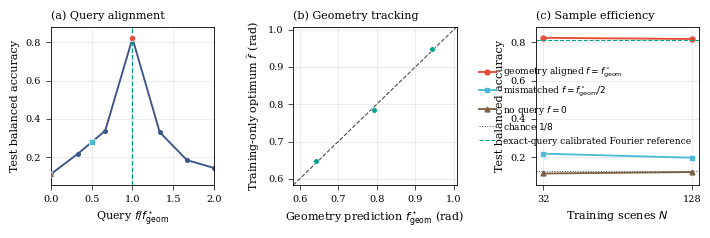

saved /home/felix/SAR-QML/notebooks/sar_geometry_outputs/sar_geometry_smoke_fb481d2cdf18.pdf


In [ ]:
# =============================================================================
# Main figure
# =============================================================================
COLORS = {
    "aligned": "#E64B35",
    "wrong": "#4DBBD5",
    "none": "#7E6148",
    "scan": "#3C5488",
    "geometry": "#00A087",
    "reference": "#4D4D4D",
}
LABELS = {
    "aligned": r"geometry aligned $f=f^\star_{\rm geom}$",
    "wrong": r"mismatched $f=f^\star_{\rm geom}/2$",
    "none": r"no query $f=0$",
}
MARKERS = {"aligned": "o", "wrong": "s", "none": "^"}

mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 8,
        "axes.labelsize": 8,
        "axes.titlesize": 8,
        "axes.linewidth": 0.6,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "xtick.major.width": 0.5,
        "ytick.major.width": 0.5,
        "lines.linewidth": 1.35,
        "legend.fontsize": 6.5,
    }
)

fig, axes = plt.subplots(1, 3, figsize=(7.15, 2.42))

# ---------------------------------------------------------------------- (a) --
axis = axes[0]
axis.fill_between(
    SCAN_X,
    SCAN_SUMMARY["lower"],
    SCAN_SUMMARY["upper"],
    color=COLORS["scan"],
    alpha=0.18,
    lw=0,
)
axis.plot(
    SCAN_X,
    SCAN_SUMMARY["mean"],
    "-o",
    color=COLORS["scan"],
    ms=2.6,
    markevery=max(1, len(SCAN_X) // 12),
)
axis.axvline(1.0, color=COLORS["geometry"], ls="--", lw=0.9)
for scale, arm in [(0.0, "none"), (0.5, "wrong"), (1.0, "aligned")]:
    index = int(np.argmin(np.abs(SCAN_X - scale)))
    axis.plot(
        SCAN_X[index],
        SCAN_SUMMARY["mean"][index],
        marker=MARKERS[arm],
        color=COLORS[arm],
        mec="white",
        mew=0.45,
        ms=4.4,
        ls="none",
        zorder=5,
    )
axis.set_xlim(0.0, 2.0)
axis.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
axis.set_xlabel(r"Query $f/f^\star_{\rm geom}$")
axis.set_ylabel("Test balanced accuracy")
axis.set_title("(a) Query alignment", loc="left")
axis.grid(True, alpha=0.22)

# ---------------------------------------------------------------------- (b) --
axis = axes[1]
x = RECOVERY_SUMMARY["f_geom"].to_numpy()
y = RECOVERY_SUMMARY["f_hat"].to_numpy()
low = y - RECOVERY_SUMMARY["lower95"].to_numpy()
high = RECOVERY_SUMMARY["upper95"].to_numpy() - y
limit_low = min(x.min(), y.min()) - 0.06
limit_high = max(x.max(), y.max()) + 0.06
axis.plot(
    [limit_low, limit_high],
    [limit_low, limit_high],
    color=COLORS["reference"],
    lw=0.8,
    ls="--",
)
axis.errorbar(
    x,
    y,
    yerr=np.vstack([low, high]),
    fmt="o",
    color=COLORS["geometry"],
    ecolor=COLORS["geometry"],
    elinewidth=0.8,
    capsize=2,
    ms=4.0,
    mec="white",
    mew=0.45,
)
axis.set_xlim(limit_low, limit_high)
axis.set_ylim(limit_low, limit_high)
axis.set_xlabel(r"Geometry prediction $f^\star_{\rm geom}$ (rad)")
axis.set_ylabel(r"Training-only optimum $\widehat f$ (rad)")
axis.set_title("(b) Geometry tracking", loc="left")
axis.grid(True, alpha=0.22)

# ---------------------------------------------------------------------- (c) --
axis = axes[2]
for arm in ("aligned", "wrong", "none"):
    summary = EFFICIENCY_SUMMARY[arm]
    axis.fill_between(
        summary["n"],
        summary["lower"],
        summary["upper"],
        color=COLORS[arm],
        alpha=0.14,
        lw=0,
    )
    axis.plot(
        summary["n"],
        summary["mean"],
        marker=MARKERS[arm],
        color=COLORS[arm],
        ms=3.5,
        label=LABELS[arm],
    )
axis.axhline(
    1.0 / Q,
    color=COLORS["reference"],
    lw=0.7,
    ls=":",
    label=f"chance $1/{Q}$",
)
axis.axhline(
    EXACT_QFT_REFERENCE,
    color=COLORS["geometry"],
    lw=0.8,
    ls="--",
    label="exact-query calibrated Fourier reference",
)
axis.set_xscale("log", base=2)
axis.set_xticks(P["efficiency_ns"])
axis.set_xticklabels([str(value) for value in P["efficiency_ns"]])
axis.set_xlabel("Training scenes $N$")
axis.set_ylabel("Test balanced accuracy")
axis.set_title("(c) Sample efficiency", loc="left")
axis.grid(True, alpha=0.22)
axis.legend(frameon=False, loc="best", handlelength=1.8)

all_lower = np.concatenate(
    [
        SCAN_SUMMARY["lower"],
        *[EFFICIENCY_SUMMARY[arm]["lower"] for arm in ARMS],
        [1.0 / Q],
    ]
)
all_upper = np.concatenate(
    [
        SCAN_SUMMARY["upper"],
        *[EFFICIENCY_SUMMARY[arm]["upper"] for arm in ARMS],
        [EXACT_QFT_REFERENCE],
    ]
)
padding = max(0.025, 0.08 * (all_upper.max() - all_lower.min()))
y_limits = (
    max(0.0, all_lower.min() - padding),
    min(1.01, all_upper.max() + padding),
)
axes[0].set_ylim(*y_limits)
axes[2].set_ylim(*y_limits)

fig.tight_layout(w_pad=1.25)
FIGURE_STEM = OUTDIR / f"sar_geometry_{PROFILE}_{RUN_ID}"
fig.savefig(FIGURE_STEM.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(FIGURE_STEM.with_suffix(".png"), dpi=400, bbox_inches="tight")
plt.show()
print(f"saved {FIGURE_STEM.with_suffix('.pdf').resolve()}")

## Geometry diagnostic

The following auxiliary figure makes the approximation used by the circuit
explicit. The scene generator uses the sampled nonuniform \(\omega\)-\(k\)
interaction, whereas the query uses its compact bilinear term. The residual is
small but nonzero, so the aligned circuit implements a task-informed
approximation rather than an exact inverse.

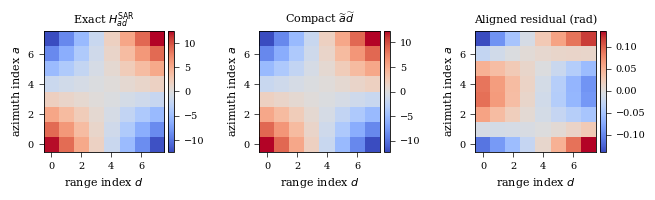

In [ ]:
# =============================================================================
# Auxiliary geometry figure
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(6.7, 1.95))
images = [
    (H_EXACT, r"Exact $H^{\rm SAR}_{ad}$"),
    (H_COMPACT, r"Compact $\widetilde a\widetilde d$"),
    (F_STAR * (H_EXACT - H_COMPACT), "Aligned residual (rad)"),
]
for axis, (matrix, title) in zip(axes, images):
    image = axis.imshow(matrix, origin="lower", cmap="coolwarm", aspect="equal")
    axis.set_title(title)
    axis.set_xlabel("range index $d$")
    axis.set_ylabel("azimuth index $a$")
    fig.colorbar(image, ax=axis, fraction=0.047, pad=0.03)
fig.tight_layout(w_pad=1.0)
geometry_stem = OUTDIR / f"sar_geometry_kernel_{PROFILE}_{RUN_ID}"
fig.savefig(geometry_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(geometry_stem.with_suffix(".png"), dpi=350, bbox_inches="tight")
plt.show()

## Saved summaries and manuscript caption

The numerical summaries below are suitable for direct manuscript use only for
the paper profile. If the audit warnings fire, the corresponding claim must be
revised rather than the data-generation or optimization settings being tuned
after inspecting the test set.

In [ ]:
# =============================================================================
# Save summaries, provenance, and caption
# =============================================================================
scan_table = pd.DataFrame(
    {
        "f_over_star": SCAN_X,
        "mean": SCAN_SUMMARY["mean"],
        "lower95": SCAN_SUMMARY["lower"],
        "upper95": SCAN_SUMMARY["upper"],
    }
)
efficiency_rows = []
for arm, summary in EFFICIENCY_SUMMARY.items():
    for index, n_train in enumerate(summary["n"]):
        efficiency_rows.append(
            {
                "arm": arm,
                "n_train": int(n_train),
                "mean": float(summary["mean"][index]),
                "lower95": float(summary["lower"][index]),
                "upper95": float(summary["upper"][index]),
            }
        )
efficiency_table = pd.DataFrame(efficiency_rows)

scan_table.to_csv(OUTDIR / f"scan_summary_{PROFILE}_{RUN_ID}.csv", index=False)
RECOVERY_SUMMARY.to_csv(
    OUTDIR / f"recovery_summary_{PROFILE}_{RUN_ID}.csv", index=False
)
efficiency_table.to_csv(
    OUTDIR / f"efficiency_summary_{PROFILE}_{RUN_ID}.csv", index=False
)

summary_payload = {
    "run_id": RUN_ID,
    "geometry": GEOMETRY,
    "validity": VALIDITY,
    "audit": AUDIT,
    "paired_effects": PAIRED_EFFECTS,
}
(OUTDIR / f"summary_{PROFILE}_{RUN_ID}.json").write_text(
    json.dumps(summary_payload, indent=2)
)

caption = r"""\textbf{Geometry-aligned classification of unfocused SAR-like
phase histories.}
(a) Test balanced accuracy as the fixed query is varied relative to
$f^\star_{\rm geom}$, calculated from the acquisition geometry and reference
slant range. The circuit is retrained independently at every query value.
(b) Training-loss optimum $\widehat f$ versus the geometry prediction when the
reference range is varied; test data are not used to obtain $\widehat f$.
(c) Sample efficiency of the geometry-aligned, mismatched, and no-query
circuits. All arms use the same amplitude encoding, 12-parameter readout, data,
and paired initializations. Curves show means over independent scene draws and
shaded regions show 95\% bootstrap intervals over draws. The dashed reference
uses the exact geometry query and the known inverse sensor calibration followed
by the fixed Fourier readout."""
caption_path = OUTDIR / f"caption_{PROFILE}_{RUN_ID}.tex"
caption_path.write_text(caption)

display(scan_table)
display(RECOVERY_SUMMARY)
display(efficiency_table)
print("\nCaption draft:\n")
print(caption)

if PROFILE != "paper":
    print(
        "\nThis is a smoke-test result only. Set PROFILE='paper', restart the "
        "kernel, and run all cells before using any result in the manuscript."
    )

,f_over_star,mean,lower95,upper95
0,0.000000,0.11000,0.11000,0.11000
1,0.333333,0.21750,0.21750,0.21750
2,0.500000,0.27750,0.27750,0.27750
3,0.666667,0.33750,0.33750,0.33750
4,1.000000,0.82125,0.82125,0.82125
5,1.333333,0.33000,0.33000,0.33000
6,1.666667,0.18375,0.18375,0.18375
7,2.000000,0.14250,0.14250,0.14250


,f_geom,f_hat,lower95,upper95
0,0.642974,0.648924,0.648924,0.648924
1,0.793002,0.784830,0.784830,0.784830
2,0.943029,0.947589,0.947589,0.947589


,arm,n_train,mean,lower95,upper95
0,aligned,32,0.82375,0.82375,0.82375
1,aligned,128,0.81750,0.81750,0.81750
2,wrong,32,0.21750,0.21750,0.21750
3,wrong,128,0.19625,0.19625,0.19625
4,none,32,0.11375,0.11375,0.11375
5,none,128,0.12125,0.12125,0.12125



Caption draft:

\textbf{Geometry-aligned classification of unfocused SAR-like
phase histories.}
(a) Test balanced accuracy as the fixed query is varied relative to
$f^\star_{\rm geom}$, calculated from the acquisition geometry and reference
slant range. The circuit is retrained independently at every query value.
(b) Training-loss optimum $\widehat f$ versus the geometry prediction when the
reference range is varied; test data are not used to obtain $\widehat f$.
(c) Sample efficiency of the geometry-aligned, mismatched, and no-query
circuits. All arms use the same amplitude encoding, 12-parameter readout, data,
and paired initializations. Curves show means over independent scene draws and
shaded regions show 95\% bootstrap intervals over draws. The dashed reference
uses the exact geometry query and the known inverse sensor calibration followed
by the fixed Fourier readout.

This is a smoke-test result only. Set PROFILE='paper', restart the kernel, and run all cells before using any r

## Scope and primary references

This experiment isolates one local focusing mechanism. It does not model the
transmitted pulse, antenna pattern, platform motion errors, radiometric
calibration, speckle statistics of an extended scene, or the complete Stolt
interpolation pipeline. Accordingly, the manuscript should describe the input
as an **unfocused SAR-like spectral phase history**, not as operational raw SAR
data.

The wavenumber-domain construction follows the standard range-migration
relation \(k_y=\sqrt{k_r^2-k_x^2}\), for which Stolt interpolation maps the
sampled \((k_x,k_r)\) data to a Cartesian wavenumber grid:

- B. Hosseiny *et al.*, “Range Migration Algorithm in the Processing Chain of
  Signals of a Ground-Based SAR Sensor,” *ISPRS Archives* **XLII-4/W18**,
  521–525 (2019),
  [doi:10.5194/isprs-archives-XLII-4-W18-521-2019](https://doi.org/10.5194/isprs-archives-XLII-4-W18-521-2019).
- A. Reigber *et al.*, “Extended wavenumber-domain synthetic aperture radar
  focusing with integrated motion compensation,” *IEE Proc. Radar Sonar
  Navig.* **153**, 301–310 (2006),
  [doi:10.1049/ip-rsn:20045087](https://doi.org/10.1049/ip-rsn:20045087).